## Experiment 09: Density-Based Spatial Clustering (DBSCAN)
## Title: Density-Based Clustering using DBSCAN - Identifying Cluster Structure and Noise Points

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Concentric Density Rings with Outlier Noise (`sklearn.datasets.make_circles` + uniform noise)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_circles
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Generate Non-Convex Spatial Dataset with Background Noise
We construct concentric circular manifolds embedded with random spatial noise points.

Total dataset shape: (550, 2) (500 cluster points + 50 noise outliers)


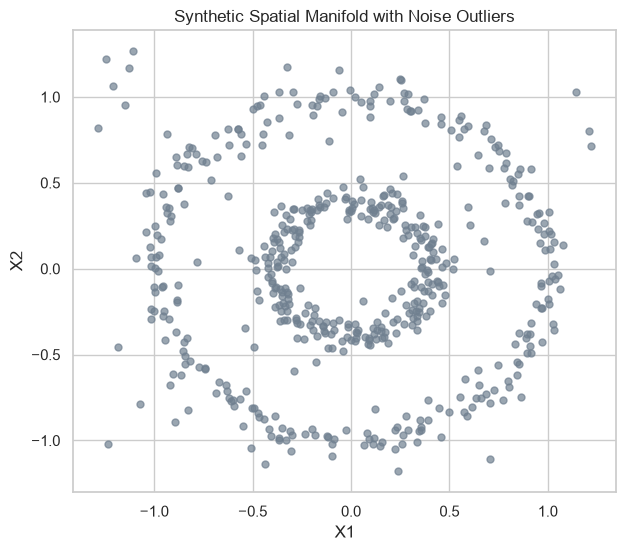

In [2]:
np.random.seed(42)

# Generate inner and outer circles
X_circles, _ = make_circles(n_samples=500, factor=0.4, noise=0.05, random_state=42)

# Add uniform random background noise
X_noise = np.random.uniform(low=-1.3, high=1.3, size=(50, 2))

# Combine datasets
X = np.vstack([X_circles, X_noise])
print(f"Total dataset shape: {X.shape} (500 cluster points + 50 noise outliers)")

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], color='slategray', s=25, alpha=0.7)
plt.title("Synthetic Spatial Manifold with Noise Outliers")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

### Step 3: Determine Optimal Epsilon (eps) via Sorted k-Distance Graph
By plotting sorted distances to the $k$-th nearest neighbor ($k = \text{min\_samples}$), the sharp 'knee' indicates optimal $\varepsilon$.

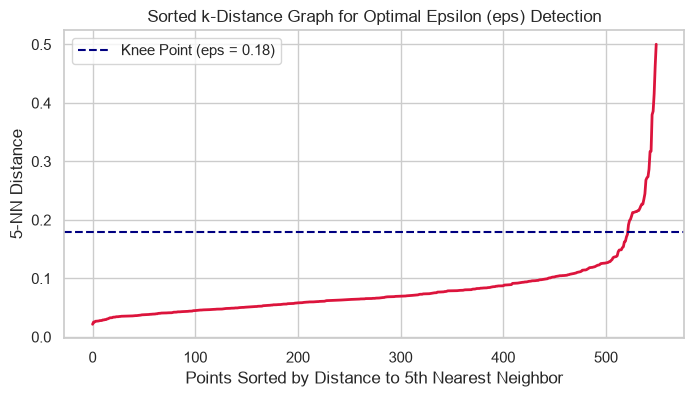

In [3]:
k = 5
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X)
distances, indices = nn.kneighbors(X)

# Sort distances to the 5th neighbor
k_distances = np.sort(distances[:, k - 1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances, color='crimson', lw=2)
plt.axhline(y=0.18, color='navy', linestyle='--', label='Knee Point (eps = 0.18)')
plt.xlabel("Points Sorted by Distance to 5th Nearest Neighbor")
plt.ylabel("5-NN Distance")
plt.title("Sorted k-Distance Graph for Optimal Epsilon (eps) Detection")
plt.legend()
plt.show()

### Step 4: Fit DBSCAN & Identify Core, Border, and Noise Points

In [4]:
dbscan = DBSCAN(eps=0.18, min_samples=5)
labels = dbscan.fit_predict(X)

# Core points
core_mask = np.zeros_like(labels, dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = np.sum(labels == -1)

print(f"Number of discovered density clusters: {n_clusters_}")
print(f"Number of identified noise outliers : {n_noise_} ({n_noise_/len(X)*100:.1f}%)")
print(f"Number of core samples               : {core_mask.sum()}")
print(f"Number of border samples             : {len(X) - core_mask.sum() - n_noise_}")

Number of discovered density clusters: 2
Number of identified noise outliers : 18 (3.3%)
Number of core samples               : 522
Number of border samples             : 10


### Step 5: Side-by-Side Comparison: DBSCAN vs. K-Means
Demonstrates why distance-based partitioning (K-Means) fails on non-convex geometric manifolds.

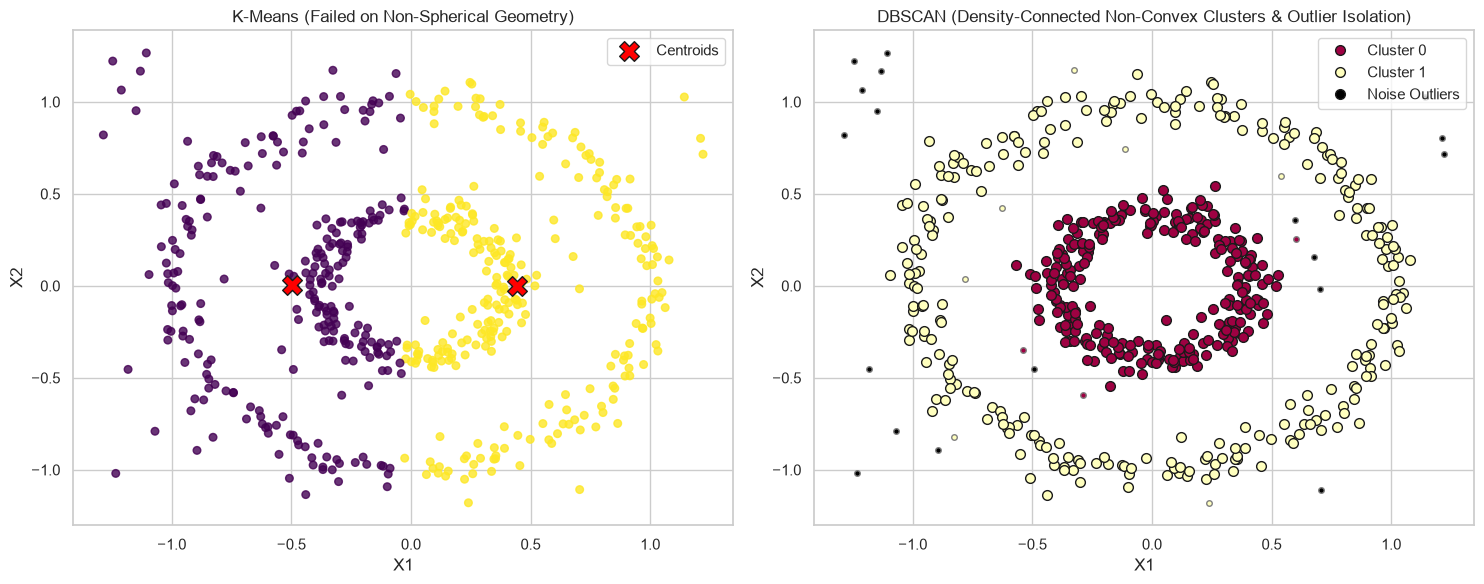

In [5]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# K-Means clustering
axes[0].scatter(X[:, 0], X[:, 1], c=km_labels, cmap='viridis', s=30, alpha=0.8)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                s=200, c='red', marker='X', edgecolor='k', label='Centroids')
axes[0].set_title("K-Means (Failed on Non-Spherical Geometry)")
axes[0].set_xlabel("X1")
axes[0].set_ylabel("X2")
axes[0].legend()

# DBSCAN clustering
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k_label, col in zip(unique_labels, colors):
    if k_label == -1:
        col = [0, 0, 0, 1]  # Black for noise
    class_member_mask = (labels == k_label)
    
    xy = X[class_member_mask & core_mask]
    axes[1].plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='k', markersize=7, label=f'Cluster {k_label}' if k_label != -1 else 'Noise Outliers')
    
    xy_noise = X[class_member_mask & ~core_mask]
    axes[1].plot(xy_noise[:, 0], xy_noise[:, 1], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='gray', markersize=4)

axes[1].set_title("DBSCAN (Density-Connected Non-Convex Clusters & Outlier Isolation)")
axes[1].set_xlabel("X1")
axes[1].set_ylabel("X2")
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### Step 6: Parameter Sensitivity Grid

In [6]:
eps_vals = [0.10, 0.18, 0.25]
min_samples_vals = [3, 5, 10]

grid_records = []
for e in eps_vals:
    for ms in min_samples_vals:
        db = DBSCAN(eps=e, min_samples=ms)
        lbs = db.fit_predict(X)
        n_c = len(set(lbs)) - (1 if -1 in lbs else 0)
        n_n = np.sum(lbs == -1)
        grid_records.append({
            'eps': e,
            'min_samples': ms,
            'Discovered Clusters': n_c,
            'Noise Outliers': n_n
        })

print(pd.DataFrame(grid_records).to_string(index=False))

 eps  min_samples  Discovered Clusters  Noise Outliers
0.10            3                    5              39
0.10            5                   11              44
0.10           10                    5             252
0.18            3                    3               8
0.18            5                    2              18
0.18           10                    2              18
0.25            3                    3               2
0.25            5                    2               6
0.25           10                    1              11


### Step 7: Conclusion
- K-Means operates under spherical Euclidean assumptions and fundamentally fails on concentric ring geometry.
- DBSCAN successfully identified the continuous density-connected non-convex contours.
- The sorted $k$-distance graph provided a mathematically grounded heuristic for choosing optimal $\varepsilon = 0.18$.
- Background noise points were robustly flagged with label `-1` without distorting the true cluster boundaries.